In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm

ERROR 1: PROJ: proj_create_from_database: Open of /home/dnash/miniconda3/envs/SEAK-impacts/share/proj failed
/home/dnash/miniconda3/envs/SEAK-impacts/lib/python3.12/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'gini' loading failed:
Struct() takes at most 1 argument (3 given)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


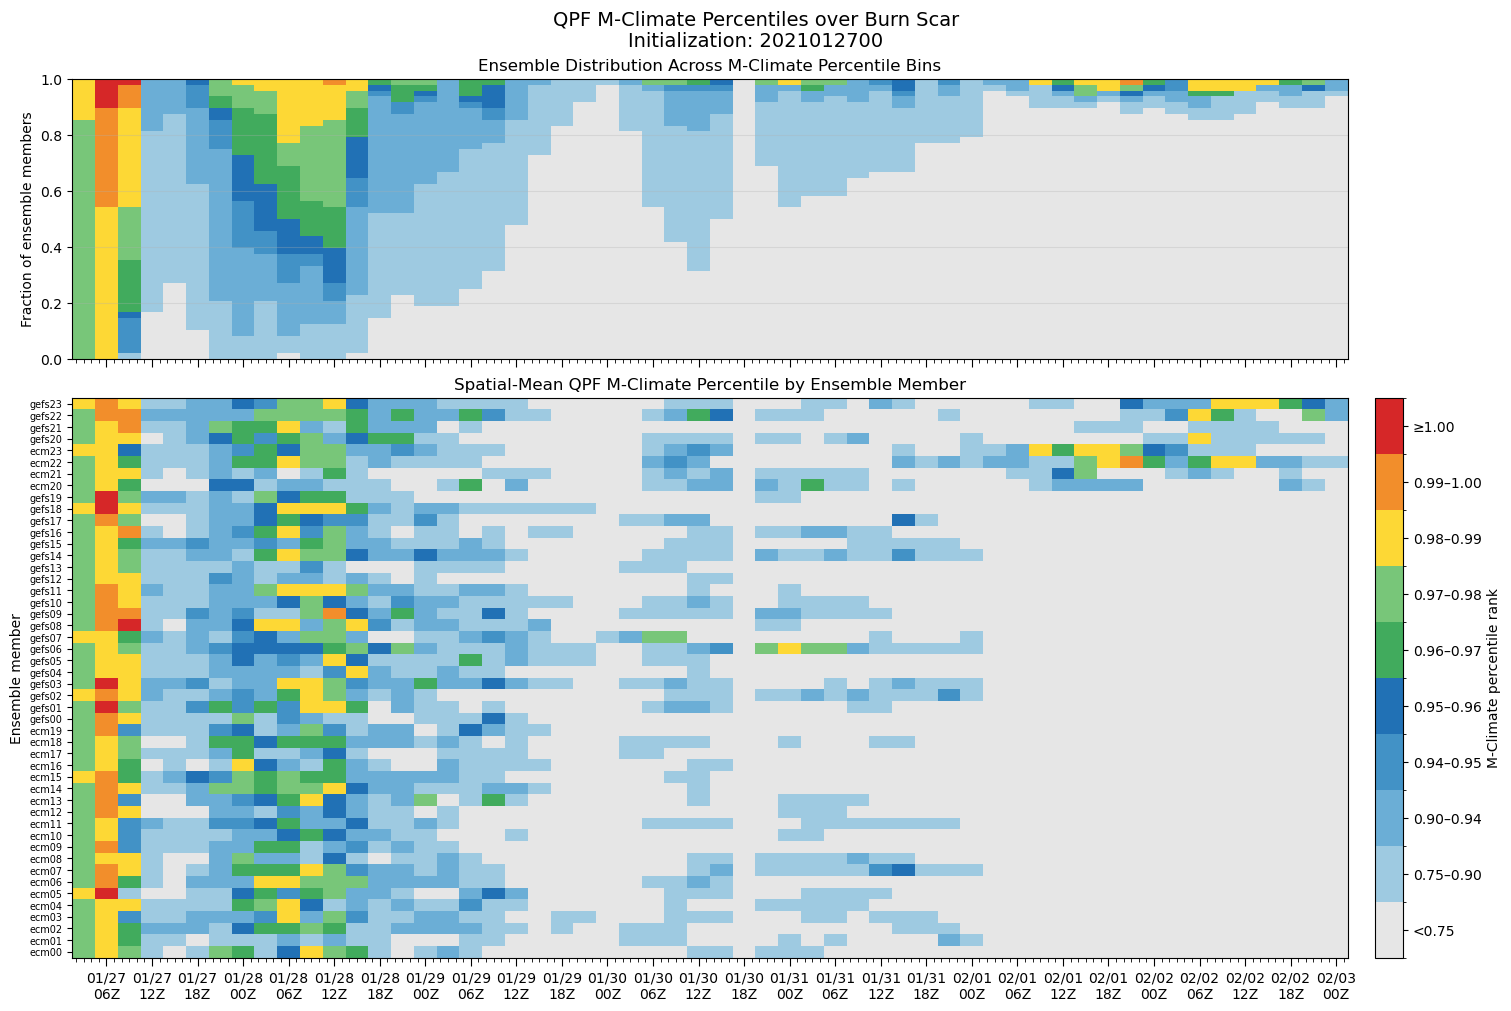

In [2]:
# ---------------------------------------------------------
# Load data
# ---------------------------------------------------------
init_date = "2021012700"
varname='qpf'
fname='test_ensemble_clip_burnscar.nc'
qpf_mean = xr.open_dataset(fname)
qpf_mean = qpf_mean[varname]
# ---------------------------------------------------------
# Prepare data
# ---------------------------------------------------------

# Convert valid times to pandas datetime objects
valid_times = pd.to_datetime(qpf_mean["valid_time"].values)

# Dimensions: (lead_time, number)
percentiles = qpf_mean.transpose("lead_time", "number").values

# Probability that ensemble members meet or exceed each threshold
thresholds = np.array([
    0.75, 0.90, 0.94, 0.95, 0.96,
    0.97, 0.98, 0.99, 1.00
])

# Percentile bins
bin_edges = np.array([
    0.0, 0.75, 0.90, 0.94, 0.95, 0.96,
    0.97, 0.98, 0.99, 1.00, 1.01
])

bin_fractions = np.array([
    np.nanmean(
        (percentiles >= lower) &
        (percentiles < upper),
        axis=1
    )
    for lower, upper in zip(bin_edges[:-1], bin_edges[1:])
])


# ---------------------------------------------------------
# Colors
# ---------------------------------------------------------

# One color for each threshold in the probability panel
threshold_colors = [
    "#E6E6E6",  # <75th
    "#9ECAE1",  # 75th
    "#6BAED6",  # 90th
    "#4292C6",  # 94th
    "#2171B5",  # 95th
    "#41AB5D",  # 96th
    "#78C679",  # 97th
    "#FDD835",  # 98th
    "#F28E2B",  # 99th
    "#D62728",  # 100th
]

# Bins: <75th, 75-90th, 90-94th, ..., 99-100th, >=100th
boundaries = [
    0.0, 0.75, 0.90, 0.94, 0.95,
    0.96, 0.97, 0.98, 0.99, 1.00,
    1.000001
]

bin_labels = [
    "<0.75", "0.75–0.90", "0.90–0.94",
    "0.94–0.95", "0.95–0.96", "0.96–0.97",
    "0.97–0.98", "0.98–0.99", "0.99–1.00", "≥1.00",
]

cmap = ListedColormap(threshold_colors)
norm = BoundaryNorm(boundaries, cmap.N)

# ---------------------------------------------------------
# Create figure
# ---------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 2]},
    constrained_layout=True
)

# ---------------------------------------------------------
# Panel 1: Stacked fraction of ensemble members in each bin
# ---------------------------------------------------------

bar_width = 3 / 24  # 3 hours

n_bins = len(bin_edges) - 1
bottom = np.zeros(len(valid_times))

for i in range(n_bins):
    ax1.bar(
        valid_times,
        bin_fractions[i],
        width=bar_width,
        bottom=bottom,
        color=threshold_colors[i],
        alpha=1.0,
        label=bin_labels[i],
        zorder=1
    )
    bottom += np.nan_to_num(bin_fractions[i], nan=0.0)

ax1.set_ylabel("Fraction of ensemble members")
ax1.set_ylim(0, 1.0)
ax1.set_title("Ensemble Distribution Across M-Climate Percentile Bins")
ax1.grid(axis="y", alpha=0.3)
ax1.set_yticks(np.arange(0, 1.01, 0.2))

# ---------------------------------------------------------
# Panel 2: Individual ensemble member percentile ranks
# ---------------------------------------------------------

# Transpose to (number, lead_time) for the portrait diagram
member_percentiles = percentiles.T

time_numeric = mdates.date2num(valid_times.to_pydatetime())

# Construct cell edges so each rectangle is centered on its time
if len(time_numeric) > 1:
    time_edges = np.empty(len(time_numeric) + 1)
    time_edges[1:-1] = (time_numeric[:-1] + time_numeric[1:]) / 2
    time_edges[0] = time_numeric[0] - (
        time_numeric[1] - time_numeric[0]
    ) / 2
    time_edges[-1] = time_numeric[-1] + (
        time_numeric[-1] - time_numeric[-2]
    ) / 2
else:
    time_edges = np.array([
        time_numeric[0] - 0.5,
        time_numeric[0] + 0.5
    ])

member_edges = np.arange(member_percentiles.shape[0] + 1)

mesh = ax2.pcolormesh(
    time_edges,
    member_edges,
    np.ma.masked_invalid(member_percentiles),
    cmap=cmap,
    norm=norm,
    shading="flat"
)

# Label each row with its ensemble member name
member_names = qpf_mean["number"].values
ax2.set_yticks(np.arange(len(member_names)) + 0.5)
ax2.set_yticklabels(member_names, fontsize=7)

ax2.set_ylabel("Ensemble member")
ax2.set_title("Spatial-Mean QPF M-Climate Percentile by Ensemble Member")
ax2.grid(False)

# ==========================================================
# X-axis formatting
# ==========================================================

major_locator = mdates.HourLocator(byhour=[0, 6, 12, 18])
minor_locator = mdates.HourLocator(interval=1)

major_formatter = mdates.DateFormatter("%m/%d\n%HZ")

for ax in (ax1, ax2):

    ax.xaxis.set_major_locator(major_locator)
    ax.xaxis.set_minor_locator(minor_locator)
    ax.xaxis.set_major_formatter(major_formatter)

    ax.tick_params(axis="x", which="major", length=6)
    ax.tick_params(axis="x", which="minor", length=3)

# ==========================================================
# Colorbar
# ==========================================================
cbar = fig.colorbar(
    mesh,
    ax=ax2,
    boundaries=boundaries,
    ticks=[
        0.375, 0.825, 0.92, 0.945, 0.955,
        0.965, 0.975, 0.985, 0.995, 1.0000005
    ],
    spacing="uniform",
    pad=0.015
)

cbar.set_ticklabels(bin_labels)
cbar.set_label("M-Climate percentile rank")

fig.suptitle(
    f"{varname.upper()} M-Climate Percentiles over Burn Scar\n"
    f"Initialization: {init_date}",
    fontsize=14
)

plt.show()